# 06 · Clustering collision contexts with k-modes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryam843/uk-road-accident-analytics/blob/main/notebooks/06_clustering.ipynb)

**Replaces** the original coursework's K-Means on label-encoded features (silhouette reported
as evidence of good clusters).

**Question:** do collisions fall into a few recognisable *contexts* (road, speed, light,
weather, surface, junction, area, time), and do those contexts differ in KSI share?

**Method**
- Stratified (year × KSI) sample of 100,000 collisions from 2015-2019.
- Nine pre-event categorical features from `src/features.py::context_frame`: road type, speed
  limit band, light, weather, road surface, junction detail (historic), urban/rural, hour band,
  weekday/weekend. Missing values are an explicit "Missing" category. The KSI label is **not**
  a clustering input; it is only used to profile the clusters afterwards.
- **k-modes** (Huang initialisation, matching dissimilarity) for k = 3 … 8, five seeds each:
  cost elbow plus stability (adjusted Rand index between seeds).
- Profiles: size, defining categories, KSI share with a Wilson 95% interval against the overall
  share. Cluster membership describes a context; it does not cause severity.
- Old-method comparison: K-Means on label-encoded and on one-hot features, silhouette on a
  10,000-row subsample.

**Results (this run):** 
- k = 5 chosen: the cost elbow is at k = 4-5, and k = 5 is the most stable across seeds
  (mean ARI 0.294). Stability is low for every k, so the clusters are a summary, not natural
  groups.
- **Rural high-speed roads** (29.4% of the sample) have a KSI share of 0.2312 (95% CI
  0.2264-0.2361) against 0.1825 overall (ratio 1.27). Urban roads after dark are slightly
  above average (0.1976); the three other urban clusters are below it (0.1478-0.1582). In all
  five seeds the highest-KSI cluster is 97-100% rural (KSI share 0.2312-0.2634).
- Label-encoded K-Means scores a higher silhouette (0.330) than one-hot K-Means (0.108) or
  k-modes (0.109), but its clusters change when the arbitrary integer codes are reassigned
  (ARI 0.407 between the two runs). The high silhouette is an artefact.

In [1]:
# Setup: works from the repo root, from notebooks/, or on Google Colab.
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src/config.py").exists():
    if not Path("uk-road-accident-analytics").exists():
        !git clone -q https://github.com/maryam843/uk-road-accident-analytics.git
    %cd uk-road-accident-analytics
    %pip install -q -r requirements.txt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import clean, config, evaluate

config.setup_logging(logging.INFO)
evaluate.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = config.get_data_dir()
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
if not (PROCESSED / config.COLLISIONS_PARQUET).exists():
    # Fresh runtime (e.g. Colab): download (several GB) and clean. Takes a while, once.
    from src import download

    download.main([])
    clean.run()
print("DATA_DIR =", config.display_path(DATA_DIR))

import time
from itertools import combinations

from joblib import Parallel, delayed
from kmodes.kmodes import KModes
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

from src import features

N_SAMPLE, K_RANGE, SEEDS = 100_000, range(3, 9), [config.RANDOM_STATE + i for i in range(5)]

DATA_DIR = data


## Sample and features

In [3]:
SRC = ["collision_year", "date", "hour", "speed_limit", "ksi", *features.CONTEXT_SOURCES.values()]
coll = pd.read_parquet(PROCESSED / config.COLLISIONS_PARQUET, columns=SRC)
coll = coll[coll["collision_year"].between(2015, 2019)].reset_index(drop=True)
strata = coll["collision_year"].astype(str) + "_" + coll["ksi"].astype(str)
sample_idx, _ = train_test_split(coll.index, train_size=N_SAMPLE, stratify=strata,
                                 random_state=config.RANDOM_STATE)
sample = coll.loc[np.sort(sample_idx)].reset_index(drop=True)
X = features.context_frame(sample)
y_ksi = sample["ksi"].astype(int).to_numpy()
OVERALL = y_ksi.mean()
print(f"Population 2015-2019: {len(coll):,} collisions, KSI share {coll['ksi'].mean():.4f}")
print(f"Sample: {len(sample):,} collisions, KSI share {OVERALL:.4f}")
display(pd.DataFrame({"categories": X.nunique(), "missing_share": (X == features.MISSING_CATEGORY).mean(),
                      "most_common": X.mode().iloc[0],
                      "most_common_share": [X[c].value_counts(normalize=True).iloc[0] for c in X]})
        .style.format({"missing_share": "{:.2%}", "most_common_share": "{:.1%}"}))

Population 2015-2019: 646,830 collisions, KSI share 0.1826
Sample: 100,000 collisions, KSI share 0.1825


,categories,missing_share,most_common,most_common_share
road_type,6,0.00%,Single carriageway,73.5%
light,6,0.00%,Daylight,72.3%
weather,10,0.01%,Fine no high winds,80.9%
surface,6,0.90%,Dry,72.2%
junction,10,0.47%,Not at junction or within 20 metres,41.4%
urban_rural,3,0.00%,Urban,66.3%
speed_band,5,0.02%,30,61.2%
hour_band,5,0.00%,10-15 daytime,35.0%
day_type,2,0.00%,Weekday,75.8%


## Choosing k: cost elbow and stability across seeds

Each (k, seed) pair is one k-modes run with Huang initialisation. **Cost** is the total
number of mismatches between collisions and their cluster mode (lower is better, always falls
as k grows). **Stability** is the adjusted Rand index (ARI) between the partitions from the
five seeds (10 pairs): 1 means the same clusters every time, 0 means chance agreement.

30 k-modes runs in 78 s


,best_cost,mean_cost,mean_ari,min_ari,cost_drop_vs_k_minus_1
k,,,,,
3,"258,247","268,971",0.102,0.017,nan%
4,"231,019","250,457",0.143,0.024,10.5%
5,"222,644","228,437",0.294,0.200,3.6%
6,"215,205","222,519",0.285,0.173,3.3%
7,"203,633","213,866",0.275,0.183,5.4%
8,"198,422","205,952",0.233,0.131,2.6%


23:38:12 INFO src.evaluate: Saved figure reports/figures/06_kmodes_choice.png


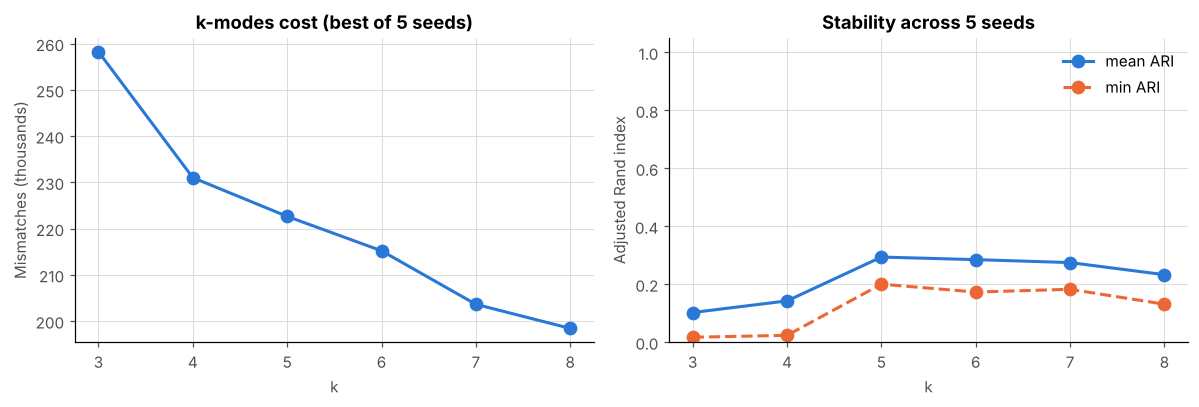

In [4]:
def fit_kmodes(k, seed):
    model = KModes(n_clusters=k, init="Huang", n_init=1, max_iter=100, random_state=seed)
    labels = model.fit_predict(X.to_numpy())
    return k, seed, model.cost_, labels, model.cluster_centroids_


t0 = time.time()
runs = Parallel(n_jobs=-1)(delayed(fit_kmodes)(k, s) for k in K_RANGE for s in SEEDS)
print(f"{len(runs)} k-modes runs in {time.time() - t0:,.0f} s")
fits = {(k, s): (cost, labels, cents) for k, s, cost, labels, cents in runs}
rows = []
for k in K_RANGE:
    costs = [fits[(k, s)][0] for s in SEEDS]
    aris = [adjusted_rand_score(fits[(k, a)][1], fits[(k, b)][1]) for a, b in combinations(SEEDS, 2)]
    rows.append({"k": k, "best_cost": min(costs), "mean_cost": np.mean(costs),
                 "mean_ari": np.mean(aris), "min_ari": np.min(aris)})
choice = pd.DataFrame(rows).set_index("k")
choice["cost_drop_vs_k_minus_1"] = -choice["best_cost"].pct_change()
display(choice.style.format({"best_cost": "{:,.0f}", "mean_cost": "{:,.0f}", "mean_ari": "{:.3f}",
                             "min_ari": "{:.3f}", "cost_drop_vs_k_minus_1": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(choice.index, choice["best_cost"] / 1000, marker="o", markersize=8)
axes[0].set_title("k-modes cost (best of 5 seeds)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Mismatches (thousands)")
axes[1].plot(choice.index, choice["mean_ari"], marker="o", markersize=8, label="mean ARI")
axes[1].plot(choice.index, choice["min_ari"], marker="o", markersize=8, linestyle="--", label="min ARI")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Stability across 5 seeds")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Adjusted Rand index")
axes[1].legend()
fig.tight_layout()
evaluate.save_fig(fig, "06_kmodes_choice")
plt.show()

**Choice: k = 5.** The cost falls by 10.5% from k = 3 to 4, then by only 3.6% and 3.3% for
k = 5 and 6, so the elbow is around k = 4-5. Stability decides between them: k = 5 has the
highest mean ARI across seeds (0.294) and the highest minimum (0.200). That stability is still
**low** for every k (mean ARI 0.102-0.294): different seeds give noticeably different
partitions, and taking the best of 5 initialisations per seed did not change this in a
design-time check. So these clusters are one useful summary of collision contexts, not natural
groups in the data. The profiles below use the lowest-cost seed, and the check at the end of
the next cell shows whether the main finding (the high-KSI cluster) survives a change of seed.

In [5]:
K = 5
best_seed = min(SEEDS, key=lambda s: fits[(K, s)][0])
labels = fits[(K, best_seed)][1]
print(f"k = {K}: using seed {best_seed} (lowest cost {fits[(K, best_seed)][0]:,.0f}); "
      f"mean ARI across seeds {choice.loc[K, 'mean_ari']:.3f}")

overall_share = {c: X[c].value_counts(normalize=True) for c in X}
prof_rows, defining = [], {}
for c in range(K):
    m = labels == c
    lo, hi = evaluate.wilson_interval(y_ksi[m].sum(), m.sum())
    row = {"cluster": c, "size": int(m.sum()), "share": m.mean(), "ksi_share": y_ksi[m].mean(),
           "ksi_low": float(lo), "ksi_high": float(hi), "ksi_ratio_vs_overall": y_ksi[m].mean() / OVERALL}
    lifts = []
    for col in X:
        vc = X.loc[m, col].value_counts(normalize=True)
        row[col] = f"{vc.index[0]} ({vc.iloc[0]:.0%})"
        for cat, sh in vc.items():
            if sh >= 0.25:
                lifts.append((sh / overall_share[col][cat], col, cat, sh))
    defining[c] = sorted(lifts, reverse=True)[:4]
    prof_rows.append(row)
profile = pd.DataFrame(prof_rows).set_index("cluster")
print(f"Overall KSI share in the sample: {OVERALL:.4f}")
display(profile[["size", "share", "ksi_share", "ksi_low", "ksi_high", "ksi_ratio_vs_overall"]]
        .style.format({"share": "{:.1%}", "ksi_share": "{:.4f}", "ksi_low": "{:.4f}",
                       "ksi_high": "{:.4f}", "ksi_ratio_vs_overall": "{:.2f}"}))
print("Modal category per feature (share of the cluster):")
display(profile[list(X.columns)].T)
print("Most over-represented categories (share in cluster >= 25%; lift = share in cluster / overall share):")
for c, items in defining.items():
    print(f"  cluster {c}: " + "; ".join(f"{col}={cat} ({sh:.0%}, lift {lift:.2f})"
                                       for lift, col, cat, sh in items))

print(f"Highest-KSI cluster in each seed's k = {K} partition (does the main finding depend on the seed?):")
for s in SEEDS:
    lab = fits[(K, s)][1]
    shares = pd.Series(y_ksi).groupby(lab).mean()
    top = int(shares.idxmax())
    m = lab == top
    print(f"  seed {s}: KSI share {shares.max():.4f}, size {m.sum():,}, rural {(X.loc[m, 'urban_rural'] == 'Rural').mean():.0%}, "
          f"60-70 mph {(X.loc[m, 'speed_band'] == '60-70').mean():.0%}")

k = 5: using seed 42 (lowest cost 222,644); mean ARI across seeds 0.294
Overall KSI share in the sample: 0.1825


,size,share,ksi_share,ksi_low,ksi_high,ksi_ratio_vs_overall
cluster,,,,,,
0,29437,29.4%,0.2312,0.2264,0.2361,1.27
1,9469,9.5%,0.1538,0.1466,0.1612,0.84
2,35021,35.0%,0.1582,0.1545,0.1621,0.87
3,12004,12.0%,0.1976,0.1906,0.2048,1.08
4,14069,14.1%,0.1478,0.1420,0.1537,0.81


Modal category per feature (share of the cluster):


cluster,0,1,2,3,4
road_type,Single carriageway (71%),Dual carriageway (74%),Single carriageway (86%),Single carriageway (79%),Single carriageway (86%)
light,Daylight (78%),Daylight (82%),Daylight (78%),Darkness - lights lit (92%),Daylight (100%)
weather,Fine no high winds (80%),Fine no high winds (82%),Fine no high winds (82%),Fine no high winds (75%),Fine no high winds (84%)
surface,Dry (67%),Dry (75%),Dry (76%),Dry (62%),Dry (80%)
junction,Not at junction or within 20 metres (64%),Not at junction or within 20 metres (46%),T or staggered junction (63%),Not at junction or within 20 metres (51%),Not at junction or within 20 metres (62%)
urban_rural,Rural (99%),Urban (89%),Urban (93%),Urban (90%),Urban (100%)
speed_band,60-70 (63%),40-50 (59%),30 (88%),30 (85%),30 (92%)
hour_band,10-15 daytime (41%),10-15 daytime (45%),16-19 evening peak (52%),20-23 evening (62%),10-15 daytime (82%)
day_type,Weekday (73%),Weekday (77%),Weekday (80%),Weekday (69%),Weekday (77%)


Most over-represented categories (share in cluster >= 25%; lift = share in cluster / overall share):
  cluster 0: speed_band=60-70 (63%, lift 3.22); urban_rural=Rural (99%, lift 2.93); junction=Not at junction or within 20 metres (64%, lift 1.53); hour_band=10-15 daytime (41%, lift 1.16)
  cluster 1: road_type=Dual carriageway (74%, lift 4.91); speed_band=40-50 (59%, lift 4.71); urban_rural=Urban (89%, lift 1.34); hour_band=10-15 daytime (45%, lift 1.30)
  cluster 2: junction=T or staggered junction (63%, lift 2.07); hour_band=16-19 evening peak (52%, lift 1.76); speed_band=30 (88%, lift 1.43); urban_rural=Urban (93%, lift 1.41)
  cluster 3: hour_band=20-23 evening (62%, lift 5.42); light=Darkness - lights lit (92%, lift 4.58); speed_band=30 (85%, lift 1.38); surface=Wet or damp (34%, lift 1.37)
  cluster 4: hour_band=10-15 daytime (82%, lift 2.33); urban_rural=Urban (100%, lift 1.51); junction=Not at junction or within 20 metres (62%, lift 1.50); speed_band=30 (92%, lift 1.49)
Highest

**Cluster names** (from the defining categories above, seed 42):

| Cluster | Name | Why |
|---|---|---|
| 0 | Rural high-speed roads | 99% rural, 63% at 60-70 mph, mostly away from junctions |
| 1 | Urban dual carriageways, 40-50 mph | 74% dual carriageway, 59% at 40-50 mph |
| 2 | Urban 30 mph junctions, evening peak | 63% T or staggered junctions, 52% at 16-19, 88% at 30 mph |
| 3 | Urban roads after dark | 92% darkness with lights lit, 62% at 20-23 |
| 4 | Urban 30 mph daytime, away from junctions | 100% daylight, 82% at 10-15, 92% at 30 mph |

Only the rural high-speed cluster has a clearly higher KSI share than average (0.2312 vs
0.1825, ratio 1.27). Urban roads after dark are slightly above average (0.1976); the three
other urban clusters are below it. The finding does not depend on the seed: in all five k = 5 runs the highest-KSI cluster is
97-100% rural with 63-78% of collisions at 60-70 mph (KSI share 0.2312-0.2634). This repeats what notebook 04 found with a supervised
model: speed limit and rural roads go with severity. It describes contexts, it does not show
that the context causes the severity.

,name,size,share,ksi_share,ksi_low,ksi_high,ksi_ratio_vs_overall
cluster,,,,,,,
0,Rural high-speed roads,29437,29.4%,0.2312,0.2264,0.2361,1.27
1,"Urban dual carriageways, 40-50 mph",9469,9.5%,0.1538,0.1466,0.1612,0.84
2,"Urban 30 mph junctions, evening peak",35021,35.0%,0.1582,0.1545,0.1621,0.87
3,Urban roads after dark,12004,12.0%,0.1976,0.1906,0.2048,1.08
4,"Urban 30 mph daytime, away from junctions",14069,14.1%,0.1478,0.1420,0.1537,0.81


23:38:13 INFO src.evaluate: Saved figure reports/figures/06_cluster_ksi_share.png


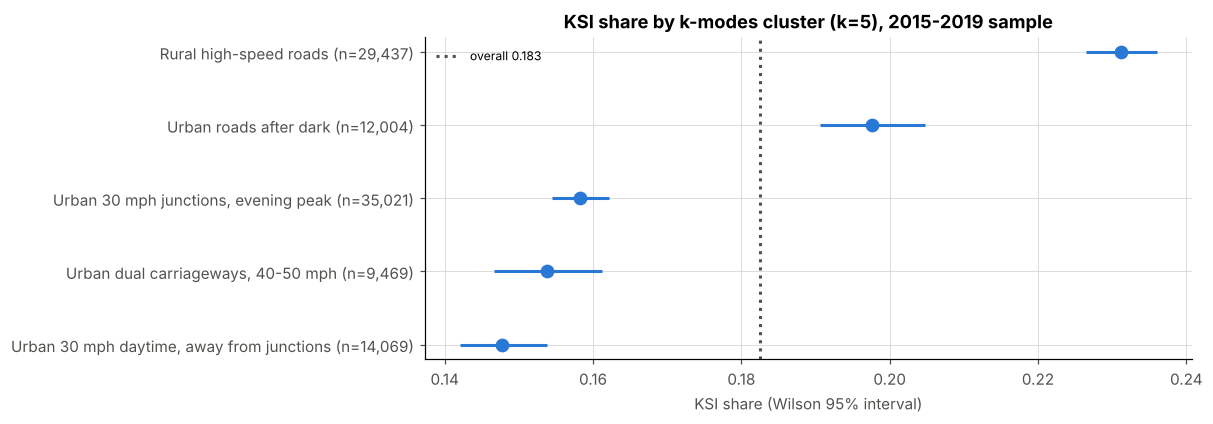

In [6]:
NAMES = {0: "Rural high-speed roads", 1: "Urban dual carriageways, 40-50 mph",
         2: "Urban 30 mph junctions, evening peak", 3: "Urban roads after dark",
         4: "Urban 30 mph daytime, away from junctions"}
profile.insert(0, "name", [NAMES[c] for c in profile.index])
display(profile[["name", "size", "share", "ksi_share", "ksi_low", "ksi_high", "ksi_ratio_vs_overall"]]
        .style.format({"share": "{:.1%}", "ksi_share": "{:.4f}", "ksi_low": "{:.4f}", "ksi_high": "{:.4f}",
                       "ksi_ratio_vs_overall": "{:.2f}"}))
fig, ax = plt.subplots(figsize=(9, 3.8))
order = profile.sort_values("ksi_share")
ax.errorbar(order["ksi_share"], range(K), xerr=[order["ksi_share"] - order["ksi_low"],
            order["ksi_high"] - order["ksi_share"]], fmt="o", markersize=8, color=evaluate.PALETTE[0])
ax.axvline(OVERALL, color="#52514e", linestyle=":", label=f"overall {OVERALL:.3f}")
ax.set_yticks(range(K), [f"{n} (n={s:,})" for n, s in zip(order["name"], order["size"], strict=True)])
ax.set_xlabel("KSI share (Wilson 95% interval)")
ax.set_title(f"KSI share by k-modes cluster (k={K}), 2015-2019 sample")
ax.legend(fontsize=8)
evaluate.save_fig(fig, "06_cluster_ksi_share")
plt.show()

## The old method: K-Means on label-encoded vs one-hot features

Same sample, same k. **Label encoding** replaces each category with an integer (here
alphabetical order, as `LabelEncoder` does), so K-Means treats "Dry" < "Flood" < "Frost" as
amounts with distances between them. **One-hot** gives each category its own 0/1 column.
Silhouettes are computed on the same 10,000-row subsample, each in its own feature space
(Euclidean), and for k-modes with the matching (Hamming) distance. To show how arbitrary
label encoding is, the integer codes are also reassigned at random and K-Means is rerun.

In [7]:
rng = np.random.default_rng(config.RANDOM_STATE)
sub = rng.choice(len(X), size=10_000, replace=False)
codes = OrdinalEncoder().fit_transform(X)  # alphabetical integer codes, like LabelEncoder per column
onehot = OneHotEncoder(sparse_output=False).fit_transform(X)
km_label = KMeans(n_clusters=K, n_init=10, random_state=config.RANDOM_STATE).fit_predict(codes)
km_onehot = KMeans(n_clusters=K, n_init=10, random_state=config.RANDOM_STATE).fit_predict(onehot)

permuted = codes.copy()
for j in range(codes.shape[1]):
    perm = rng.permutation(int(codes[:, j].max()) + 1)
    permuted[:, j] = perm[codes[:, j].astype(int)]
km_permuted = KMeans(n_clusters=K, n_init=10, random_state=config.RANDOM_STATE).fit_predict(permuted)


def ksi_range(lab):
    shares = pd.Series(y_ksi).groupby(lab).mean()
    return f"{shares.min():.3f}-{shares.max():.3f}"


comparison = pd.DataFrame({
    "silhouette (10k subsample)": [
        silhouette_score(codes[sub], km_label[sub]),
        silhouette_score(permuted[sub], km_permuted[sub]),
        silhouette_score(onehot[sub], km_onehot[sub]),
        silhouette_score(codes[sub], labels[sub], metric="hamming"),
    ],
    "ARI vs k-modes": [adjusted_rand_score(labels, lab) for lab in (km_label, km_permuted, km_onehot, labels)],
    "KSI share range across clusters": [ksi_range(lab) for lab in (km_label, km_permuted, km_onehot, labels)],
}, index=["K-Means, label-encoded (alphabetical codes)", "K-Means, label-encoded (codes reassigned at random)",
          "K-Means, one-hot", "k-modes (matching distance)"])
display(comparison.style.format({"silhouette (10k subsample)": "{:.3f}", "ARI vs k-modes": "{:.3f}"}))
print(f"ARI between the two label-encoded runs (same data, only the integer codes differ): "
      f"{adjusted_rand_score(km_label, km_permuted):.3f}")
spread = pd.Series(codes.var(axis=0), index=X.columns).sort_values(ascending=False)
print("Variance of the integer codes per feature (larger variance = more weight in the Euclidean distance):")
display(spread.to_frame("code_variance").T.style.format("{:.2f}"))

,silhouette (10k subsample),ARI vs k-modes,KSI share range across clusters
"K-Means, label-encoded (alphabetical codes)",0.330,0.088,0.155-0.208
"K-Means, label-encoded (codes reassigned at random)",0.270,0.112,0.151-0.217
"K-Means, one-hot",0.108,0.355,0.149-0.235
k-modes (matching distance),0.109,1.000,0.148-0.231


ARI between the two label-encoded runs (same data, only the integer codes differ): 0.407
Variance of the integer codes per feature (larger variance = more weight in the Euclidean distance):


,junction,surface,weather,light,road_type,hour_band,urban_rural,speed_band,day_type
code_variance,8.18,4.72,4.35,1.63,1.31,1.11,0.89,0.77,0.18


**Why label encoding is wrong for nominal data.** Label encoding turns categories into
integers in an arbitrary (here alphabetical) order, and K-Means then treats the codes as
amounts: for junction detail, "Crossroads" = 0, "Mini-roundabout" = 1, "Missing" = 2 …
"Roundabout" = 7 … "T or staggered junction" = 9, so a T-junction is nine times "further" from
a crossroads than a mini-roundabout is, and "Missing" sits between two junction types. None of
that means anything. The
results depend on the arbitrary order: reassigning the same codes at random gives a different
partition (ARI 0.407 between the two label-encoded runs). Features with more categories get
larger code ranges and dominate the distance: junction detail (10 categories) has a code
variance of 8.18, the weekday/weekend flag 0.18. The higher silhouette of the label-encoded
runs (0.330) is not evidence of better clusters. It measures separation in a made-up geometry
where integer codes form artificial bands. One-hot K-Means (0.108) and k-modes with matching
distance (0.109) have low silhouettes because collision contexts overlap heavily. That is the
honest picture, and the original project's silhouette did not show it. k-modes is used
because it works with categories directly: the distance is the number of mismatched features
and the cluster centre is the modal category of each feature.